# Python Time Machine Tests

Import relevant libraries and create fitting engine.

In [1]:
from fitting_engine import FittingEngine
import numpy as np
import matplotlib.pyplot as plt

engine = FittingEngine(verbose=True)

Define properties of the test data.

In [2]:
# slicing properties
n_points = 30
true_y_err_std = 0.05
x_length = 3

# material properties
true_order = 0.0
true_order_std = 0.0
true_sigma_phi = 5
true_mu = 5
true_f = 0.0001
f_std = 0.00001

# actual sample parameters
true_t_exposure_1 = 3_000
true_t_burial_1 = 5_000
true_t_exposure_2 = 10
true_t_burial_2 = 3_000

# calibration sample parameters
calibration_t_exposure = [10]

Generate test data from the given parameters.

In [ ]:
# generate calibration data with random perturbation from true values
calibration_x_data = []
calibration_y_data = []
calibration_y_err_std = []
for i, t_exposure in enumerate(calibration_t_exposure):
    calibration_x_data.append(np.linspace(0, x_length, n_points))
    # genearte y data using the mathematical model for single exposure
    calibration_y_data.append(engine.models.expo(calibration_x_data[i],
        true_order, true_sigma_phi, true_mu, t_exposure))
    # add random perturbation
    perturbation = np.random.normal(loc=0.0, scale=true_y_err_std,
        size=calibration_x_data[i].shape)

    calibration_y_data[i] += perturbation
    # allow only non-zero measurements
    calibration_y_data[i] = np.maximum(calibration_y_data[i], 0)

    calibration_y_err_std.append(np.full(len(calibration_x_data[0]),
        true_y_err_std))

# generate measurement sample data
x_data = np.linspace(0, x_length, n_points)
y_data = engine.models.expo_buri_expo_buri(x_data, true_order, true_sigma_phi,
    true_mu,true_f, true_t_exposure_1, true_t_burial_1, true_t_exposure_2,
    true_t_burial_2)
# add random perturbation
perturbation = np.random.normal(loc=0.0, scale=true_y_err_std,
    size=x_data[i].shape)
y_data += perturbation
# allow only non-zero measurements
y_data = np.maximum(y_data, 0)

# generate known f by perturbing the true value according to std
known_f = np.random.normal(loc=true_f, scale=f_std)

Prepare the data for the subseuent calibration fit. The multiple calibration data sets are concatenated into one large array. The `t_exposure` parameter is then given as an array for each datapoint, not as one float used for all points. This allows fitting calibration samples with different exposure at once and is the best way to handle this. 

In [4]:
# combine individual calibration samples into one large dataset
calibration_x_data_combined = np.concatenate(calibration_x_data)
calibration_y_data_combined = np.concatenate(calibration_y_data)
calibration_y_err_std_combined = np.concatenate(calibration_y_err_std)

# each datapoint gets an individual t_exposure value for the global fit
calibration_t_exposure_combined = np.concatenate(
    [np.full(n_points, t_exposure) for t_exposure in calibration_t_exposure])

# order is a scalar that is constant for all datapoints, t_exposure_1 
# can differ between datapoints because multiple calibration datasets
# can be used
known_params = {"order": true_order,
    "t_exposure_1": calibration_t_exposure_combined}
known_params_err_std = {"order": true_order_std}
bounds = {
    "sigma_phi": engine.param_bounds.val.sigma_phi,
    "mu": engine.param_bounds.val.mu
}

Perform `bayesian_fit` on the data to obtain `sigma_phi` and `mu` from the calibration.

In [5]:
# calculate calibration results
_, _, calibration_fit_result = engine.full_fit(calibration_x_data_combined,
    calibration_y_data_combined, calibration_y_err_std_combined,
    engine.models.expo, known_params, known_params_err_std, bounds=bounds,
    fit_quality=engine.fit_quality_settings.medium, only_positive=True)

calibration_success = calibration_fit_result.success
calibration_joint_samples = calibration_fit_result.joint_samples

print(calibration_success)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma_phi, mu]


/home/thorie/.conda/envs/python_time_machine/lib/python3.14/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/thorie/.conda/envs/python_time_machine/lib/python3.14/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)


Sampling 4 chains for 2_000 tune and 10_000 draw iterations (8_000 + 40_000 draws total) took 7 seconds.


True


Plot joint probability distribution of `sigma_phi` and `mu`.

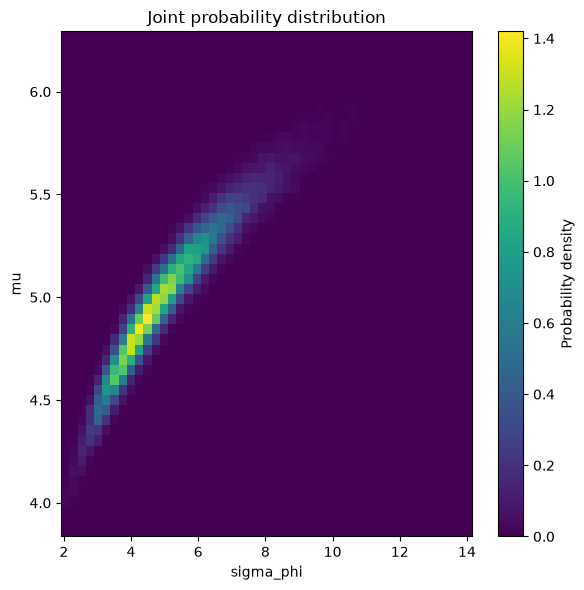

In [6]:
sigma_phi_joint = np.array(
    [sample["sigma_phi"] for sample in calibration_joint_samples])
mu_joint = np.array([sample["mu"] for sample in calibration_joint_samples])
hist, x_edges, y_edges = np.histogram2d(sigma_phi_joint, mu_joint, bins=50,
    density=True)

# plot 2d histogram
plt.figure(figsize=(6, 6))
plt.imshow(hist.T, origin="lower", aspect="auto",
    extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]],
    cmap="viridis")
plt.colorbar(label="Probability density")
plt.xlabel("sigma_phi")
plt.ylabel("mu")
plt.title("Joint probability distribution")
plt.tight_layout()
plt.show()